In [1]:
import matplotlib.pyplot as plt
import numpy as np

from superfv.tools.rk_stability import derive_ssprk3_amplification, plot_stability_region
from superfv.tools.fv_stability import plot_fv_upwind_Omega_h_over_a_harmonic_trace

In [2]:
def plot_rk3_stability(ax, n=100, **kwargs):
    x, y = np.meshgrid(np.linspace(-5,1,n), np.linspace(-3,3,n))
    z = x + 1j*y
    pp = np.abs(1+z+z**2/2+z**3/6) # RK3 amplification factor
    ax.contour(x, y, pp, **kwargs)

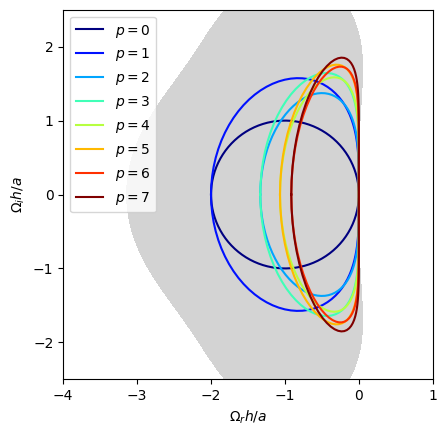

In [3]:
xlim = -4, 1
ylim = -2.5, 2.5
nmesh = 256

fig, ax = plt.subplots()
ax.set_xlabel(r"$\Omega_r h / a$")
ax.set_ylabel(r"$\Omega_i h / a$")
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect('equal')

cfl=0.8

rk3 = derive_ssprk3_amplification()
plot_stability_region(ax, rk3, np.linspace(xlim[0], xlim[1], nmesh), np.linspace(ylim[0], ylim[1], nmesh), cfl, levels=[0.0, 1.0], colors="lightgrey", fill=True)

for p in range(8):
    plot_fv_upwind_Omega_h_over_a_harmonic_trace(ax, p, color=plt.cm.jet(p / 7), label=fr"$p={p}$")

ax.legend()